In [22]:
import rawpy
import sys
import os
from pathlib import Path
import importlib
import matplotlib.pyplot as plt
from PIL import Image, ExifTags
import numpy as np
import cv2
import imageio
import tifffile
import seaborn as sns

helperFolder = Path("../helper")
if str(helperFolder.resolve()) not in sys.path:
    sys.path.insert(0, str(helperFolder.resolve()))

import utils
import psu_imaging as psu
importlib.reload(utils)
importlib.reload(psu)

<module 'psu_imaging' from 'C:\\Users\\EMMWILL\\repos\\EE513\\exercises\\helper\\psu_imaging.py'>

## Part 1

### D1

In [23]:
imagePath = 'images/cb_edge.DNG'

with rawpy.imread(imagePath) as raw:
    print(f"Color Description: {raw.color_desc}")
    print(f"Raw Pattern: {raw.raw_pattern}")

Color Description: b'RGBG'
Raw Pattern: [[2 3]
 [1 0]]


### D2

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0050462573..0.45220074].


[528. 528. 528. 528.]
[[528. 528. 528. ... 528. 528. 528.]
 [528. 528. 528. ... 528. 528. 528.]
 [528. 528. 528. ... 528. 528. 528.]
 ...
 [528. 528. 528. ... 528. 528. 528.]
 [528. 528. 528. ... 528. 528. 528.]
 [528. 528. 528. ... 528. 528. 528.]]
Pixels shape: (3024, 4032)
New image shape: (1512, 2016, 3)


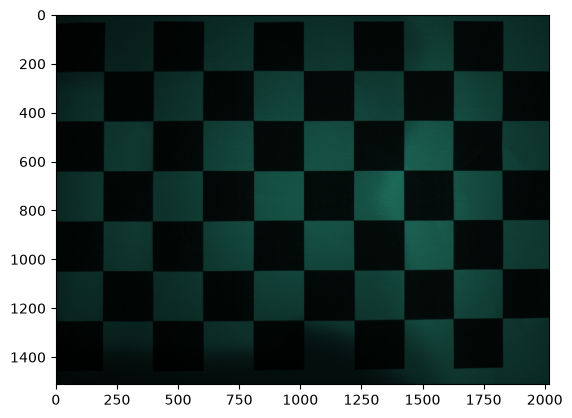

In [24]:
rawColors = {'green': np.array([]), 'red':  np.array([]), 'blue': np.array([])}
with rawpy.imread(imagePath) as raw:
    pixels = raw.raw_image_visible
    
    blackLevels = np.asarray(raw.black_level_per_channel, dtype=np.float32)
    blackMap = blackLevels[raw.raw_colors_visible]
    print(blackLevels)
    print(blackMap)
    pixels = (pixels - blackMap) / (raw.white_level - blackMap)
    
    width, height = pixels.shape
    pixels = pixels[:width - width % 2, :height - height % 2]
    
    rawColors['green'] = (pixels[1::2, 0::2] + pixels[0::2, 1::2]) / 2
    rawColors['red'] = pixels[0::2, 0::2]
    rawColors['blue'] = pixels[1::2, 1::2]
    
    newImage = np.stack((rawColors['red'], rawColors['green'], rawColors['blue']), axis=-1)
    print(f"Pixels shape: {pixels.shape}")
    print(f"New image shape: {newImage.shape}")
plt.imshow(newImage)
plt.show()


### D3

### D4

## Part 2

### D5

### D6

### D7

### D8

## Part 3

### D9

### D10

## Part 4

### D11

### D12

### D13